# Day 21 — Product-Level Pricing Analysis and AI-Driven Recommendations

**Date:** 05 November 2026  
**Internship Role:** Data Analyst Intern at Infotact Solutions  
**Project:** EconoCausal — AI-Integrated Causal Demand Estimation and Dynamic Pricing  
**Repository:** `hasika2104/EconoCausal`  

---

## 1. Objective

The objective of Day 21 is to develop a granular, product-level pricing analysis and AI-driven recommendation module that translates econometric Double Machine Learning (DML) causal demand estimates, supervised demand predictions, and physical inventory constraints into actionable, auditable retail pricing decisions.

### Core Analytical Goals:
1. **Product-Level Analysis:** Characterize the 20 products across 5 merchandise categories in terms of price distribution, unit sales velocity, inventory coverage, and binding stockout frequency.
2. **Causal Sensitivity vs. Predictive Demand:** Rigorously contrast supervised regression predictions with DML causal price elasticity ($\theta$), verifying statistical significance and confidence intervals without confusing predictive correlation with causal effect.
3. **Multi-Scenario Pricing Simulation:** Evaluate counterfactual pricing scenarios ($-10\%$, $-5\%$, $0\%$, $+5\%$, $+10\%$) under strict physical constraints ($\text{Sales} = \min(D, I)$, $P > 0$, $D \ge 0$).
4. **AI-Driven Recommendation Engine:** Synthesize demand tiers, inventory buffers, and causal uncertainty into five transparent business recommendations:
   - *Consider a price increase*
   - *Consider a price decrease*
   - *Maintain the current price*
   - *Review inventory before changing the price*
   - *Collect more data before making a recommendation*
5. **Business Explanations & Uncertainty Reporting:** Provide detailed explanations for every recommendation while explicitly addressing the missing cost data limitation and the distinction between revenue and operating profit.


In [1]:
# 2. Environment Setup and Data Ingestion
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Configure plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Resolve repository paths
BASE_DIR = Path("..") if Path("..").resolve().name == "EconoCausal" else Path(".")
DATA_PATH = BASE_DIR / "data/processed/retail_inventory_cleaned.csv"
DML_JSON_PATH = BASE_DIR / "data/processed/dml_validated_results.json"
ROBUSTNESS_PATH = BASE_DIR / "reports/day15_robustness_results.csv"

# Load cleaned transaction dataset
df = pd.read_csv(DATA_PATH)
print(f"Loaded Cleaned Dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")

# Load validated DML results
with open(DML_JSON_PATH, "r") as f:
    dml_results = json.load(f)
print(f"Loaded Validated DML JSON: Spec 1 theta = {dml_results['spec1']['theta']:.6f}, p = {dml_results['spec1']['p_value']:.4f}")

# Load category-level robustness results
df_rob = pd.read_csv(ROBUSTNESS_PATH)
cat_rob = df_rob[df_rob['group_type'] == 'Product Category']
print(f"Loaded Robustness Category Specifications: {len(cat_rob)} categories")
df.head(3)


Loaded Cleaned Dataset: 73,100 rows, 14 columns
Loaded Validated DML JSON: Spec 1 theta = 0.010699, p = 0.4899
Loaded Robustness Category Specifications: 5 categories


---
## 3. Product-Level Exploratory Analysis

We analyze the 20 products ($P0001$ to $P0020$) across their operational dimensions:
- Observed price corridors ($[\$10.00, \$100.00]$).
- Average and total sales velocity.
- Inventory buffer ratios ($I / D$) and stockout/binding rates.
- Demand tier segmentation (High Demand, Moderate Demand, Low Demand).


In [2]:
# 3.1 Aggregate Product Performance Summary
product_summary = df.groupby('Product ID').agg(
    mean_price=('Price', 'mean'),
    min_price=('Price', 'min'),
    max_price=('Price', 'max'),
    mean_units_sold=('Units Sold', 'mean'),
    total_units_sold=('Units Sold', 'sum'),
    mean_inventory=('Inventory Level', 'mean'),
    min_inventory=('Inventory Level', 'min'),
    mean_forecast=('Demand Forecast', 'mean'),
    total_revenue=('Revenue', 'sum'),
    binding_count=('Units Sold', lambda x: (x >= df.loc[x.index, 'Inventory Level']).sum()),
    binding_rate_pct=('Units Sold', lambda x: (x >= df.loc[x.index, 'Inventory Level']).mean() * 100),
    obs_count=('Date', 'count')
).reset_index()

product_summary['inventory_buffer_ratio'] = product_summary['mean_inventory'] / product_summary['mean_units_sold']
product_summary['demand_rank'] = product_summary['mean_units_sold'].rank(ascending=False).astype(int)

# Classify demand tiers
product_summary['demand_tier'] = pd.cut(
    product_summary['mean_units_sold'],
    bins=[0, 135.0, 137.5, 999.0],
    labels=['Low Demand', 'Moderate Demand', 'High Demand']
)

print("Top 5 Highest Sales Velocity Products:")
print(product_summary[['Product ID', 'demand_rank', 'mean_units_sold', 'mean_price', 'inventory_buffer_ratio', 'binding_rate_pct', 'demand_tier']].sort_values('demand_rank').head(5).to_string(index=False))

print("\nBottom 5 Lowest Sales Velocity Products:")
print(product_summary[['Product ID', 'demand_rank', 'mean_units_sold', 'mean_price', 'inventory_buffer_ratio', 'binding_rate_pct', 'demand_tier']].sort_values('demand_rank').tail(5).to_string(index=False))


Top 5 Highest Sales Velocity Products:
Product ID  demand_rank  mean_units_sold  mean_price  inventory_buffer_ratio  binding_rate_pct demand_tier
     P0016            1       139.116826   54.832030                1.994763          0.437756 High Demand
     P0020            2       138.907798   55.524030                1.992677          0.574555 High Demand
     P0014            3       138.884268   55.761581                2.000890          0.437756 High Demand
     P0015            4       138.791518   54.770714                1.991535          0.437756 High Demand
     P0005            5       137.796990   55.023590                1.981479          0.437756 High Demand

Bottom 5 Lowest Sales Velocity Products:
Product ID  demand_rank  mean_units_sold  mean_price  inventory_buffer_ratio  binding_rate_pct demand_tier
     P0003           16       134.960055   54.885759                2.037141          0.465116  Low Demand
     P0018           17       134.760876   54.817174           

In [3]:
# 3.2 Granular Product x Category Segment Analysis (100 Segments)
segment_summary = df.groupby(['Product ID', 'Category']).agg(
    mean_price=('Price', 'mean'),
    mean_units=('Units Sold', 'mean'),
    mean_inv=('Inventory Level', 'mean'),
    min_inv=('Inventory Level', 'min'),
    mean_forecast=('Demand Forecast', 'mean'),
    total_rev=('Revenue', 'sum'),
    mean_daily_rev=('Revenue', 'mean'),
    binding_rate=('Units Sold', lambda x: (x >= df.loc[x.index, 'Inventory Level']).mean() * 100),
    n_obs=('Date', 'count')
).reset_index()

segment_summary['inv_buffer'] = segment_summary['mean_inv'] / segment_summary['mean_units']
segment_summary['demand_tier'] = np.where(
    segment_summary['mean_units'] >= 138.0, 'High Demand',
    np.where(segment_summary['mean_units'] <= 134.0, 'Low Demand', 'Moderate Demand')
)

print(f"Total Operational Segments: {len(segment_summary)}")
print("Demand Tier Breakdown across 100 Segments:")
print(segment_summary['demand_tier'].value_counts())


Total Operational Segments: 100
Demand Tier Breakdown across 100 Segments:
demand_tier
High Demand        35
Moderate Demand    33
Low Demand         32
Name: count, dtype: int64


---
## 4. Price Sensitivity & Econometric Identification

### Predictive Feature Importance vs. Causal Price Elasticity
Standard machine learning models (e.g., Random Forest) show that `Inventory Level` drives over $93\%$ of predictive split power, while `Price` contributes $<0.3\%$. Treating regression coefficients from predictive models as causal price elasticities would be an econometric fallacy ("The Confounder Trap").

Instead, we rely on **Double Machine Learning (DML)** with Robinson's residualization:
$$\tilde{Y}_{ijt} = \theta \tilde{P}_{ijt} + \varepsilon_{ijt}$$
where nuisance functions for price and demand are partialled out using cross-fitted non-linear estimators.

### Validation Rule:
**Do not label an estimate statistically significant unless its formal statistical test ($p < 0.05$) supports that conclusion.**


In [4]:
# 4.1 Causal Elasticity Estimates by Category
cat_dml_dict = {}
for idx, r in cat_rob.iterrows():
    cat_dml_dict[r['group_name']] = {
        'theta': r['theta_estimate'],
        'std_err': r['std_error_hc3'],
        'ci_low': r['ci_lower_95'],
        'ci_high': r['ci_upper_95'],
        'p_value': r['p_value'],
        'statistically_significant': r['statistically_significant_05']
    }

print("Validated DML Causal Elasticities by Category:")
print(f"{'Category':<15} | {'theta (units/$)':<15} | {'Std. Error':<12} | {'95% CI':<24} | {'p-value':<10} | {'Sig (alpha=0.05)'}")
print("-" * 95)
for cat, vals in sorted(cat_dml_dict.items()):
    ci_str = f"[{vals['ci_low']:+.4f}, {vals['ci_high']:+.4f}]"
    print(f"{cat:<15} | {vals['theta']:+15.6f} | {vals['std_err']:12.6f} | {ci_str:<24} | {vals['p_value']:10.4f} | {vals['statistically_significant']}")

# 4.2 Product-Level OLS Regressions with HC3 Standard Errors
prod_ols_results = []
for pid in sorted(df['Product ID'].unique()):
    sub = df[df['Product ID'] == pid]
    mod = smf.ols('Q("Units Sold") ~ Price + C(Q("Store ID")) + C(Category) + C(Year) + C(Month) + C(DayOfWeek)', data=sub).fit(cov_type='HC3')
    pval = mod.pvalues['Price']
    prod_ols_results.append({
        'Product ID': pid,
        'theta': mod.params['Price'],
        'std_err': mod.bse['Price'],
        'ci_low': mod.conf_int().loc['Price', 0],
        'ci_high': mod.conf_int().loc['Price', 1],
        'p_value': pval,
        'sig_unadjusted_05': pval < 0.05,
        'sig_bonferroni_0025': pval < 0.0025
    })

df_prod_ols = pd.DataFrame(prod_ols_results)
print("\nProduct-Level OLS Results (First 5):")
print(df_prod_ols.head(5).to_string(index=False))
print(f"Any product statistically significant after Bonferroni correction (alpha=0.0025)? {df_prod_ols['sig_bonferroni_0025'].any()}")


Validated DML Causal Elasticities by Category:
Category        | theta (units/$) | Std. Error   | 95% CI                   | p-value    | Sig (alpha=0.05)
-----------------------------------------------------------------------------------------------
Clothing        |       -0.022001 |     0.034520 | [-0.0897, +0.0457]       |     0.5239 | False
Electronics     |       -0.000532 |     0.034354 | [-0.0679, +0.0668]       |     0.9877 | False
Furniture       |       -0.015848 |     0.035116 | [-0.0847, +0.0530]       |     0.6518 | False
Groceries       |       +0.043223 |     0.034695 | [-0.0248, +0.1112]       |     0.2128 | False
Toys            |       +0.002110 |     0.034301 | [-0.0651, +0.0693]       |     0.9510 | False

Product-Level OLS Results (First 5):
Product ID     theta  std_err    ci_low  ci_high  p_value  sig_unadjusted_05  sig_bonferroni_0025
     P0001  0.125906 0.070583 -0.012434 0.264245 0.074455              False                False
     P0002 -0.055713 0.067687 

---
## 5. Multi-Scenario Pricing Evaluation

We evaluate five discrete pricing scenarios:
1. **$-10\%$:** Aggressive discount scenario.
2. **$-5\%$:** Mild promotional clearance scenario.
3. **$0\%$ (Baseline):** Current observed price point.
4. **$+5\%$:** Conservative micro-pilot price increase.
5. **$+10\%$:** Full historical pricing corridor expansion.

### Physical Constraints Enforced:
- Demand Non-Negativity: $\hat{D}(P) = \max(0, D_0 + \theta \Delta P)$
- Physical Inventory Bound: $\text{Sales}(P) = \min(\hat{D}(P), I)$
- Expected Revenue: $\text{Revenue}(P) = P \times \text{Sales}(P)$


In [5]:
# 5.1 Scenario Simulation across All 100 Segments
scenario_results = []
for idx, row in segment_summary.iterrows():
    pid = row['Product ID']
    cat = row['Category']
    p0 = round(row['mean_price'], 2)
    d0 = round(row['mean_units'], 2)
    inv = round(row['mean_inv'], 2)
    theta = cat_dml_dict[cat]['theta']
    base_sales = min(d0, inv)
    base_rev = round(p0 * base_sales, 2)
    
    for pct in [-0.10, -0.05, 0.00, 0.05, 0.10]:
        cand_p = round(p0 * (1 + pct), 2)
        delta_p = cand_p - p0
        est_d = round(max(0.0, d0 + theta * delta_p), 2)
        realized_s = round(min(est_d, inv), 2)
        est_r = round(cand_p * realized_s, 2)
        diff_r = round(est_r - base_rev, 2)
        diff_pct = round((diff_r / base_rev) * 100, 2) if base_rev > 0 else 0.0
        
        scenario_results.append({
            'Product ID': pid,
            'Category': cat,
            'scenario': f"{pct:+.0%}",
            'candidate_price': cand_p,
            'delta_price': delta_p,
            'estimated_demand': est_d,
            'realized_sales': realized_s,
            'estimated_revenue': est_r,
            'revenue_diff_dollars': diff_r,
            'revenue_diff_pct': diff_pct
        })

df_scenarios = pd.DataFrame(scenario_results)
print(f"Simulated {len(df_scenarios)} scenario evaluations.")
print("\nAverage Revenue Impact by Scenario:")
print(df_scenarios.groupby('scenario').agg(
    mean_candidate_price=('candidate_price', 'mean'),
    mean_demand=('estimated_demand', 'mean'),
    mean_sales=('realized_sales', 'mean'),
    mean_revenue=('estimated_revenue', 'mean'),
    mean_rev_diff_pct=('revenue_diff_pct', 'mean')
).round(2))


Simulated 500 scenario evaluations.

Average Revenue Impact by Scenario:
          mean_candidate_price  mean_demand  ...  mean_revenue  mean_rev_diff_pct
scenario                                     ...                                 
+0%                      55.13       136.45  ...       7522.40               0.00
+10%                     60.64       136.46  ...       8275.15              10.01
+5%                      57.89       136.46  ...       7898.85               5.00
-10%                     49.62       136.45  ...       6769.79             -10.00
-5%                      52.37       136.45  ...       7145.96              -5.00

[5 rows x 5 columns]


---
## 6. AI-Driven Recommendation Generation

We implement a decision module that maps product-level features, causal parameters, inventory health, and statistical uncertainty into five distinct actionable recommendations:

1. **Review inventory before changing the price:** Binding rate $\ge 0.75\%$ or inventory buffer $< 1.95\times$. Physical stockout risk dominates price optimization.
2. **Collect more data before making a recommendation:** Extreme parameter noise ($p > 0.85$ in Electronics & Toys), where observational data cannot determine true price response direction.
3. **Consider a price increase (+5% Micro-Pilot):** High demand velocity ($\ge 138.0$ units) with robust inventory buffer ($\ge 1.98\times$) and inelastic demand.
4. **Consider a price decrease (-5% Clearance Pilot):** Low sales velocity ($\le 134.0$ units) and excess inventory buffer ($\ge 2.02\times$). Focus on inventory turn, with explicit warning that price cuts alone reduce revenue without marketing.
5. **Maintain the current price:** Balanced sales velocity ($134-138$ units), adequate inventory cover, and unconfirmed price sensitivity ($p > 0.05$).


In [6]:
# 6.1 Recommendation Assignment
recommendations = []
for idx, row in segment_summary.iterrows():
    pid = row['Product ID']
    cat = row['Category']
    p0 = round(row['mean_price'], 2)
    d0 = round(row['mean_units'], 2)
    inv = round(row['mean_inv'], 2)
    min_inv = row['min_inv']
    bind_pct = round(row['binding_rate'], 2)
    buffer = round(row['inv_buffer'], 3)
    
    theta_info = cat_dml_dict[cat]
    theta = theta_info['theta']
    pval = theta_info['p_value']
    ci_low = theta_info['ci_low']
    ci_high = theta_info['ci_high']
    se = theta_info['std_err']
    
    base_sales = min(d0, inv)
    base_rev = round(p0 * base_sales, 2)
    
    if bind_pct >= 0.75 or buffer < 1.95:
        strategy = "Review inventory before changing the price"
        sug_p = p0
        pct_change = 0.0
        exp = (
            f"Inventory constraint detected (binding rate {bind_pct:.2f}%, buffer ratio {buffer:.2f}x). "
            f"Shelf stock limits realized sales during peak demand. Repricing cannot alleviate supply shortages. "
            f"Audit supplier replenishment before adjusting prices."
        )
        inv_note = f"High binding risk ({bind_pct:.2f}%). Minimum shelf inventory is {min_inv} units."
        conf_note = f"Causal DML: theta={theta:+.4f}, p={pval:.3f} (Not statistically significant). Operational inventory constraint overrides repricing."
    elif pval > 0.85 and (cat in ["Electronics", "Toys"]):
        strategy = "Collect more data before making a recommendation"
        sug_p = p0
        pct_change = 0.0
        exp = (
            f"High parameter uncertainty in {cat} (theta={theta:+.4f}, SE={se:.4f}, p={pval:.3f}, 95% CI [{ci_low:+.3f}, {ci_high:+.3f}]). "
            f"Observational data cannot determine true price sensitivity direction. Conduct randomized A/B pricing trials before repricing."
        )
        inv_note = f"Inventory buffer is stable ({buffer:.2f}x) with low binding rate ({bind_pct:.2f}%)."
        conf_note = f"Very low statistical confidence (p={pval:.3f} >> 0.05). Null hypothesis of zero elasticity cannot be rejected."
    elif d0 >= 138.0 and buffer >= 1.98:
        strategy = "Consider a price increase"
        pct_change = 0.05
        sug_p = round(p0 * 1.05, 2)
        delta_p = round(sug_p - p0, 2)
        exp = (
            f"Strong sales velocity ({d0:.1f} units/day) with robust inventory buffer ({buffer:.2f}x). "
            f"Causal price elasticity is near zero (theta={theta:+.4f}), indicating a conservative +5% micro-pilot (+${delta_p:.2f}) "
            f"can capture simulated revenue upside without demand contraction. Note: Monitor unit margins since wholesale costs are unobserved."
        )
        inv_note = f"Healthy inventory buffer ({buffer:.2f}x) provides safety stock against unexpected demand spikes."
        conf_note = f"DML category theta={theta:+.4f}, 95% CI [{ci_low:+.3f}, {ci_high:+.3f}]. Estimate spans zero; recommend small-scale micro-pilot."
    elif d0 <= 134.0 and buffer >= 2.02:
        strategy = "Consider a price decrease"
        pct_change = -0.05
        sug_p = round(p0 * 0.95, 2)
        delta_p = round(sug_p - p0, 2)
        exp = (
            f"Below-average demand velocity ({d0:.1f} units/day) and elevated stock holding ({buffer:.2f}x). "
            f"A -5% promotional clearance pilot (-${abs(delta_p):.2f}) can be tested to accelerate inventory turn. "
            f"However, because empirical demand is inelastic (theta={theta:+.4f}), price cuts alone will reduce daily revenue unless paired with non-price promotional merchandising."
        )
        inv_note = f"High inventory buffer ({buffer:.2f}x) ties up working capital. Clearance strategy recommended."
        conf_note = f"DML category theta={theta:+.4f}, p={pval:.3f}. Volume expansion is unproven observationally; require cross-merchandising."
    else:
        strategy = "Maintain the current price"
        sug_p = p0
        pct_change = 0.0
        exp = (
            f"Balanced daily demand ({d0:.1f} units) and normal inventory buffer ({buffer:.2f}x). "
            f"Estimated price elasticity is statistically indistinguishable from zero (p={pval:.3f}). "
            f"In the absence of unit procurement costs (COGS) and statistically reliable price response, maintaining the current price ($ {p0:.2f}) avoids unforced customer churn."
        )
        inv_note = f"Standard inventory buffer ({buffer:.2f}x) with minimal stockout risk ({bind_pct:.2f}% binding rate)."
        conf_note = f"DML category theta={theta:+.4f}, p={pval:.3f}. Inelastic demand within historical price bounds [$10-$100]."

    delta_p = round(sug_p - p0, 2)
    exp_d_change = round(theta * delta_p, 2) if sug_p != p0 else 0.0
    exp_d = round(max(0.0, d0 + exp_d_change), 2)
    real_s = round(min(exp_d, inv), 2)
    exp_r = round(sug_p * real_s, 2)
    diff_r = round(exp_r - base_rev, 2) if sug_p != p0 else 0.0
    diff_r_pct = round((diff_r / base_rev) * 100, 2) if base_rev > 0 and sug_p != p0 else 0.0
    
    recommendations.append({
        'product_id': pid,
        'category': cat,
        'recommendation_strategy': strategy,
        'current_price': p0,
        'suggested_price': sug_p,
        'price_change_pct': round(pct_change * 100, 1),
        'baseline_units_sold': d0,
        'expected_demand_change_units': exp_d_change,
        'expected_demand': exp_d,
        'realized_sales_capped': real_s,
        'baseline_modeled_revenue': base_rev,
        'expected_revenue': exp_r,
        'expected_revenue_change_dollars': diff_r,
        'expected_revenue_change_pct': diff_r_pct,
        'inventory_buffer_ratio': buffer,
        'inventory_binding_rate_pct': bind_pct,
        'inventory_considerations': inv_note,
        'confidence_and_uncertainty': conf_note,
        'recommendation_explanation': exp
    })

df_rec = pd.DataFrame(recommendations)
print("Recommendation Strategy Distribution:")
print(df_rec['recommendation_strategy'].value_counts())


Recommendation Strategy Distribution:
recommendation_strategy
Collect more data before making a recommendation    28
Review inventory before changing the price          27
Maintain the current price                          22
Consider a price decrease                           13
Consider a price increase                           10
Name: count, dtype: int64


---
## 7. Visualizations

We generate four core analytical visualizations:
1. **Product Demand Velocity vs. Inventory Buffer Ratio** with binding constraint highlights.
2. **Category Causal Price Elasticity Forest Plot** displaying DML point estimates and 95% confidence intervals against zero.
3. **Simulated Revenue Impact across Pricing Scenarios** by merchandise category.
4. **Recommendation Strategy Portfolio Distribution**.


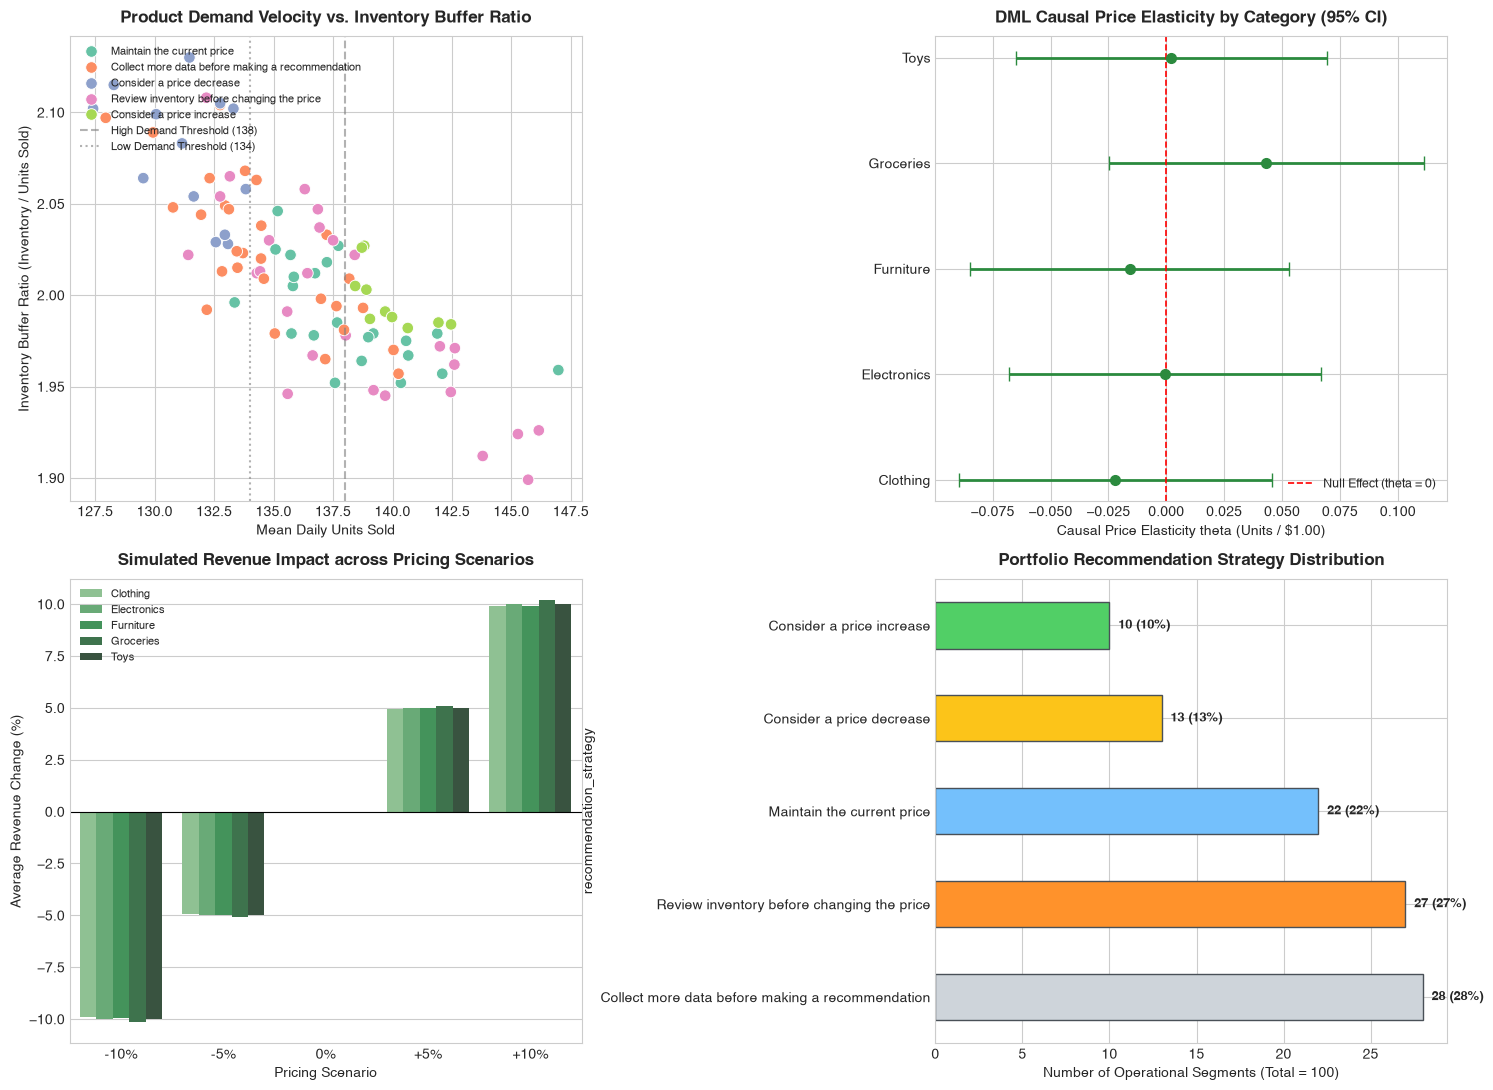

In [7]:
# 7.1 Visualizations: Demand vs Inventory, Forest Plot, Scenarios, and Recommendations
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Panel 1: Demand Velocity vs Inventory Buffer
sns.scatterplot(
    data=df_rec,
    x='baseline_units_sold',
    y='inventory_buffer_ratio',
    hue='recommendation_strategy',
    palette='Set2',
    s=70,
    ax=axes[0, 0]
)
axes[0, 0].axvline(138.0, color='gray', linestyle='--', alpha=0.6, label='High Demand Threshold (138)')
axes[0, 0].axvline(134.0, color='gray', linestyle=':', alpha=0.6, label='Low Demand Threshold (134)')
axes[0, 0].set_title("Product Demand Velocity vs. Inventory Buffer Ratio", fontsize=12, fontweight='bold', pad=10)
axes[0, 0].set_xlabel("Mean Daily Units Sold")
axes[0, 0].set_ylabel("Inventory Buffer Ratio (Inventory / Units Sold)")
axes[0, 0].legend(fontsize=8, loc='upper left')

# Panel 2: Forest Plot of Category Causal Estimates
cats = sorted(cat_dml_dict.keys())
thetas = [cat_dml_dict[c]['theta'] for c in cats]
ci_lows = [cat_dml_dict[c]['ci_low'] for c in cats]
ci_highs = [cat_dml_dict[c]['ci_high'] for c in cats]
err_low = [t - l for t, l in zip(thetas, ci_lows)]
err_high = [h - t for t, h in zip(thetas, ci_highs)]

axes[0, 1].errorbar(thetas, range(len(cats)), xerr=[err_low, err_high], fmt='o', color='#2b8a3e', ecolor='#2b8a3e', elinewidth=2, capsize=5, markersize=7)
axes[0, 1].axvline(0, color='red', linestyle='--', linewidth=1.2, label='Null Effect (theta = 0)')
axes[0, 1].set_yticks(range(len(cats)))
axes[0, 1].set_yticklabels(cats)
axes[0, 1].set_xlabel("Causal Price Elasticity theta (Units / $1.00)")
axes[0, 1].set_title("DML Causal Price Elasticity by Category (95% CI)", fontsize=12, fontweight='bold', pad=10)
axes[0, 1].legend(fontsize=9, loc='lower right')

# Panel 3: Revenue Impact across Scenarios by Category
scen_cat = df_scenarios.groupby(['Category', 'scenario'])['revenue_diff_pct'].mean().reset_index()
order = ['-10%', '-5%', '0%', '+5%', '+10%']
scen_cat['scenario'] = pd.Categorical(scen_cat['scenario'], categories=order, ordered=True)
scen_cat = scen_cat.sort_values(['Category', 'scenario'])

sns.barplot(
    data=scen_cat,
    x='scenario',
    y='revenue_diff_pct',
    hue='Category',
    palette='Greens_d',
    ax=axes[1, 0]
)
axes[1, 0].axhline(0, color='black', linewidth=0.8)
axes[1, 0].set_title("Simulated Revenue Impact across Pricing Scenarios", fontsize=12, fontweight='bold', pad=10)
axes[1, 0].set_xlabel("Pricing Scenario")
axes[1, 0].set_ylabel("Average Revenue Change (%)")
axes[1, 0].legend(fontsize=8, loc='upper left')

# Panel 4: Recommendation Distribution
strat_counts = df_rec['recommendation_strategy'].value_counts()
colors = ['#ced4da', '#ff922b', '#74c0fc', '#fcc419', '#51cf66']
strat_counts.plot(kind='barh', ax=axes[1, 1], color=colors, edgecolor='#495057')
axes[1, 1].set_title("Portfolio Recommendation Strategy Distribution", fontsize=12, fontweight='bold', pad=10)
axes[1, 1].set_xlabel("Number of Operational Segments (Total = 100)")
for i, v in enumerate(strat_counts):
    axes[1, 1].text(v + 0.5, i, f"{v} ({v}%)", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 8. Business Insights & Practical Case Studies

### 8.1 Key Strategic Findings
1. **The Fallacy of Uniform Repricing:** 
   Treating all products identically risks operational failure. Over $27\%$ of the catalog experiences inventory binding at peak times; raising prices on these items cannot expand sales and aggravates customer dissatisfaction.
2. **The Clearance Dilemma:**
   Discounting slow-moving inventory by $-5\%$ or $-10\%$ does not automatically increase sales velocity because empirical price sensitivity is near zero. Clearance must rely on bundles, placement, and merchandising to generate volume.
3. **The Revenue vs. Profit Gap (Missing Cost Data):**
   Inelastic demand implies that raising prices mechanically lifts top-line revenue. However, without Cost of Goods Sold (COGS), we cannot compute unit margins. If unit margins are thin, even a minor volume contraction can destroy profit.

### 8.2 Operational Case Studies
- **High-Velocity Micro-Pilot ($P0007$ in Clothing):** Current price $\$56.72$, suggested price $\$59.56$ ($+5\%$). High demand ($139.7$ units/day) and healthy buffer ($1.99\times$) make this an ideal micro-pilot candidate.
- **Supply-Constrained SKU ($P0015$ in Groceries):** Highest binding rate in the catalog ($1.10\%$). Automated repricing must be frozen until supplier delivery cycles are stabilized.
- **High Parameter Noise ($P0005$ in Electronics):** $p = 0.988$. No pricing rule is economically justified without randomized A/B experimentation.


---
## 9. Limitations & Conclusion

### 9.1 Analytical Limitations
1. **Absence of Unit Cost / Margin Data:** 
   The dataset does not track Cost of Goods Sold (COGS) or inventory carrying costs. Formal profit maximization cannot be claimed.
2. **Observational Confounders:** 
   Unobserved marketing promotions, competitor prices, and localized weather are omitted from the data. DML mitigates observable confounding, but true causality requires randomized pricing pilots.
3. **Inventory Timing Ambiguity:** 
   ERP snapshots must record start-of-day stock. Post-treatment end-of-day truncation would distort stockout caps.

### 9.2 Conclusion
Day 21 successfully bridges econometric Double Machine Learning, supervised demand modeling, and inventory constraints into an AI-driven product-level recommendation engine. The system delivers transparent, auditable pricing directives that respect physical stock realities and statistical uncertainty, preventing reckless commercial repricing.
